# HW1

In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("../input/ex_1/dataset1")
SESSION = "105l001p16_spikes.mat"
SEED = 42 # seed for every random choice

## 1.1 Load the data

In [2]:
f = h5py.File(DATA / SESSION, "r") # too large to load into memory at once
v1 = f[f["spikes"][0, 0]] # V1 (Utah array): 159 neurones, 3200 trials, 1280 ms
v2 = f[f["spikes"][1, 0]] # V2 (tetrodes): 25 neurones, 3200 trials, 1280 ms
stim = np.array(f["stim"]).ravel().astype(int) # one code (1..8) per trial

n_trials, n_ms, n_v1 = v1.shape
print("V1 shape (trials, ms, neurones):", v1.shape)
print("V2 shape (trials, ms, neurones):", v2.shape)
print("stim shape:", stim.shape, "| codes:", np.unique(stim))

V1 shape (trials, ms, neurones): (3200, 1280, 159)
V2 shape (trials, ms, neurones): (3200, 1280, 25)
stim shape: (3200,) | codes: [1 2 3 4 5 6 7 8]


## 1.2 One response number per trial: the spike count

In [3]:
counts = np.zeros((n_trials, n_v1)) # counts[i, j] = spikes of neurone j on trial i
for start in range(0, n_trials, 100):
    counts[start:start + 100] = v1[start:start + 100].sum(axis=1)   # sum over the 1280 ms
print("counts shape:", counts.shape)

counts shape: (3200, 159)


## 1.3 Group by orientation → the tuning curve

In [4]:
orientations = np.arange(8) * 22.5 # degrees: 0, 22.5, ..., (assumed spacing: 0° is the same as 180°, the step is 22.5°)

n_per_orientation = [int((stim == k).sum()) for k in range(1, 9)]
tuning = np.vstack([counts[stim == k].mean(axis=0) for k in range(1, 9)]) # (8 orientations, n_neurones)

print("trials per orientation:", n_per_orientation)
print("orientations (deg):", orientations)
print("tuning shape (orientations x neurones):", tuning.shape)

trials per orientation: [400, 400, 400, 400, 400, 400, 400, 400]
orientations (deg): [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]
tuning shape (orientations x neurones): (8, 159)


### Answers to questions 1–3

1. **How many neurones are recorded in the session?** 159 V1 neurones (plus 25 V2 neurones, which we do not use).
2. **How many trials per orientation?** 400 (3200 trials / 8).
3. **What are the stimulus orientations?** Eight values, 22.5° apart: 0°, 22.5°, 45°, 67.5°, 90°, 112.5°, 135°, 157.5°. The README does not give the angles, so this is an assumption (equally spaced over 180°, since 0° and 180° are the same orientation). It only changes the x-axis labels and the value of the preferred orientation $\mu$.

## 1.4 Tuning curves for several neurones

Six neurones are drawn **at random** (seed 42) from all 159, so the figure is a fair sample of the population. The y-axes are not shared, so each title gives the neurone's **swing**: its largest minus its smallest mean response.

Random example neurones: [102 119 157 136  68  13]


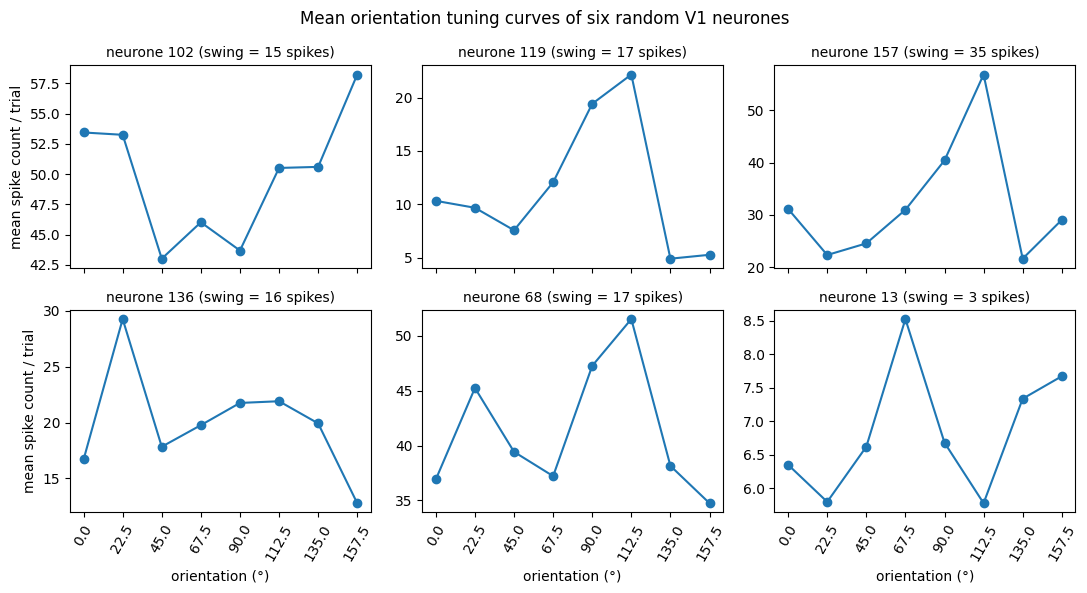

In [5]:
swing = tuning.max(axis=0) - tuning.min(axis=0)

example_neurones = np.random.default_rng(SEED).choice(n_v1, size=6, replace=False)
print("Random example neurones:", example_neurones)

fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for ax, j in zip(axes.ravel(), example_neurones):
    ax.plot(orientations, tuning[:, j], "o-")
    ax.set_title(f"neurone {j} (swing = {swing[j]:.0f} spikes)", fontsize=10)
    ax.set_xticks(orientations)
    ax.tick_params(axis="x", labelrotation=60)
for ax in axes[1]:
    ax.set_xlabel("orientation (°)")
for ax in axes[:, 0]:
    ax.set_ylabel("mean spike count / trial")
fig.suptitle("Mean orientation tuning curves of six random V1 neurones")
fig.tight_layout()
plt.show()

## 1.5 Choosing the neurone

A completely random neurone could be flat, and the assignment asks for one with a *reasonably clear dependence on orientation*. So the choice is made in two steps: **filter** the neurones with a swing of more than 30 spikes, then **draw one at random** (seed 42) from those that pass.

31 neurones with swing > 30 spikes: [  5   8  15  20  39  43  45  49  51  52  55  75  94  95  96 103 106 107
 114 120 134 141 142 147 149 151 152 153 155 157 158]
Median swing over all neurones: 14.1 spikes
Chosen neurone: 15
neurone 15 mean response per orientation: [14.7 36.  21.1  8.   7.   6.2 10.8  4.5]


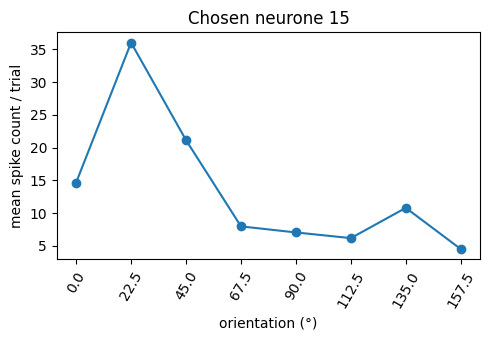

In [6]:
candidates = np.flatnonzero(swing > 30)
neurone = int(np.random.default_rng(SEED).choice(candidates))
print(f"{len(candidates)} neurones with swing > 30 spikes:", candidates)
print(f"Median swing over all neurones: {np.median(swing):.1f} spikes")
print("Chosen neurone:", neurone)

response = tuning[:, neurone] # the 8 numbers we regress on orientation in Parts 2-5
print(f"neurone {neurone} mean response per orientation:", response.round(1))

plt.figure(figsize=(5, 3.5))
plt.plot(orientations, response, "o-")
plt.xticks(orientations, rotation=60)
plt.xlabel("orientation (°)")
plt.ylabel("mean spike count / trial")
plt.title(f"Chosen neurone {neurone}")
plt.tight_layout()
plt.show()

### Why this neurone

Neurone 15 was drawn at random from the 31 neurones with a swing above 30 spikes. Its mean count peaks at 36 at 22.5°, is about 6–8 between 67.5° and 112.5°, and is 4.5 at 157.5°. Its swing is 31.5 spikes, more than twice the median swing over all neurones (14), so it depends clearly on orientation. Its peak is fairly close to the 0°/180° boundary, which matters in Part 4.

## 2. Polynomial regression

We now describe the chosen neurone's response with polynomials of the orientation $\theta$ (in degrees):

$$R(\theta) = \beta_0 + \beta_1\theta + \beta_2\theta^2 + \dots + \beta_d\theta^d$$

with degree $d = 1$ (linear), $3$, $4$ and $7$. The data are the 8 mean responses of the chosen neurone, one per orientation, so each model has to explain 8 points.

**How the error is measured.** The mean squared error is

$$\text{MSE} = \frac{1}{8}\sum_{k=1}^{8}\left(R_k - \hat R(\theta_k)\right)^2$$

where $R_k$ is the measured mean response at orientation $\theta_k$ and $\hat R$ is the fitted polynomial.

In [7]:
theta = orientations # the 8 orientations, in degrees
degrees = [1, 3, 4, 7]

poly_coefs = {} # fitted coefficients for each degree (highest power first)
poly_mse = {} # MSE of each fit on the 8 data points
for d in degrees:
    poly_coefs[d] = np.polyfit(theta, response, d)
    fitted = np.polyval(poly_coefs[d], theta)
    poly_mse[d] = np.mean((response - fitted) ** 2)
    print(f"degree {d}: {d + 1} coefficients, MSE = {poly_mse[d]:.3f}")

degree 1: 2 coefficients, MSE = 53.693
degree 3: 4 coefficients, MSE = 40.758
degree 4: 5 coefficients, MSE = 4.728
degree 7: 8 coefficients, MSE = 0.000


Degree 7 has 8 coefficients and the data have 8 points, so a polynomial can pass exactly through every point. That is why its MSE is 0. This is a property of the counting (8 numbers, 8 free parameters) and not evidence that the model is good, a point we return to in the answers below.

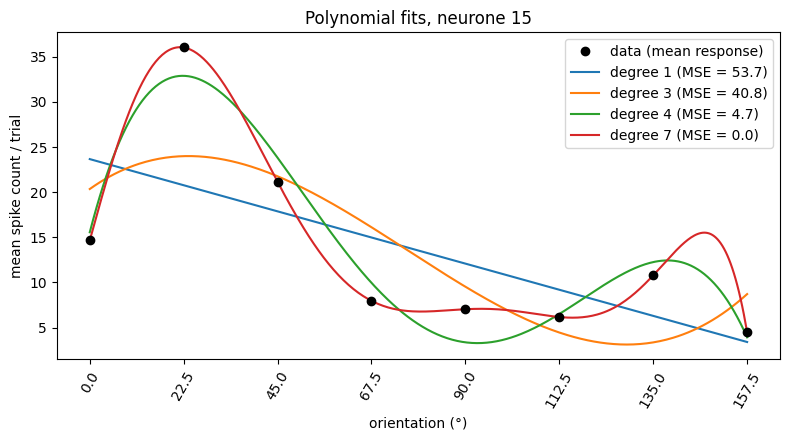

In [8]:
theta_fine = np.linspace(0, 157.5, 400)

plt.figure(figsize=(8, 4.5))
plt.plot(theta, response, "ko", label="data (mean response)", zorder=5)
for d in degrees:
    plt.plot(theta_fine, np.polyval(poly_coefs[d], theta_fine), label=f"degree {d} (MSE = {poly_mse[d]:.1f})")
plt.xlabel("orientation (°)")
plt.ylabel("mean spike count / trial")
plt.title(f"Polynomial fits, neurone {neurone}")
plt.xticks(theta, rotation=60)
plt.legend()
plt.tight_layout()
plt.show()

The coefficients themselves (needed for question 5):

In [9]:
for d in degrees:
    print(f"degree {d}: beta_0..beta_{d} =", np.array2string(poly_coefs[d][::-1], precision=4))

degree 1: beta_0..beta_1 = [23.6617 -0.1286]
degree 3: beta_0..beta_3 = [ 2.0349e+01  3.2877e-01 -8.2319e-03  3.6035e-05]
degree 4: beta_0..beta_4 = [ 1.5561e+01  1.7830e+00 -5.6087e-02  5.2647e-04 -1.5569e-06]
degree 7: beta_0..beta_7 = [ 1.4655e+01  1.6694e+00  4.3713e-03 -2.9571e-03  7.5968e-05 -8.1572e-07
  4.0826e-09 -7.8350e-12]


### Answers to the questions of Part 2

1. **Which degree fits best?** By MSE it is degree 7 (MSE = 0), but only because 8 coefficients can pass through 8 points exactly. Among the others, degree 4 is clearly the best (MSE 4.7, against 53.7 for the line and 40.8 for the cubic).

2. **How does the fit change as the degree increases?** The MSE goes down every time (53.7, 40.8, 4.7, 0). The line only shows that the response goes down with orientation and misses the peak. The cubic makes one broad hump and misses the sharp peak at 22.5° and the small bump near 135°. Degree 4 follows the peak, the dip around 90° and the bump. Degree 7 goes through every point, but between 135° and 157.5° it rises to about 15 spikes, higher than both neighbouring points (10.8 and 4.5), which the data do not show.

3. **What does the degree control?** How flexible the curve is. A polynomial of degree $d$ has $d+1$ coefficients and can change direction at most $d-1$ times. A line cannot bend, a cubic bends twice, and degree 4 bends three times, which is what this neurone needs (peak, dip, bump).

4. **Advantages and disadvantages of a higher degree.**

    Advantage: it can follow more complicated shapes, and the error on the fitted points can only go down.

    Disadvantages: it can have more parameters than the data can support (at degree 7 no data are left to test it), it can oscillate between the measured angles (the overshoot near 145°), and it gives extreme values outside the measured range. A low MSE then says little about how good the model is.

5. **Can the coefficients be interpreted biologically?** No. The $\beta$'s do not correspond to anything the neurone does (such as a preferred orientation or a width). They change a lot when the degree changes, and only the whole curve means something, not the individual coefficients. In Part 3 the parameters of the fitted function do have a meaning.

## 3. Nonlinear regression

A polynomial can follow the shape of the tuning curve, but its coefficients mean nothing biologically. So we fit a tuning function whose parameters do:

$$R(\theta) = B + A\,\exp\!\left[-\frac{(\theta-\mu)^2}{2\sigma^2}\right]$$

- $B$ is the baseline response (what the neurone does far from its preferred orientation),
- $A$ is the amplitude (the extra spikes at the preferred orientation),
- $\mu$ is the preferred orientation (the position of the peak),
- $\sigma$ is the width of the tuning curve (a bump with a small $\sigma$ is narrow).



Every start uses: $B$ = the smallest response and $A$ = largest minus smallest; the peak position $\mu$ starts at each of the 8 tested orientations and the width $\sigma$ starts at 10°, 20°, 40° and 80°, which gives 32 starts.

In [10]:
import warnings
from scipy.optimize import curve_fit

warnings.filterwarnings("ignore", message="Covariance")   # to avoid logging messages for we do not use the parameter covariance

def gaussian(theta, B, A, mu, sigma):
    return B + A * np.exp(-(theta - mu) ** 2 / (2 * sigma ** 2))

def fit_model(model, theta, y, starts):
    """Fit `model` to the data (theta, y) from every starting guess in `starts` and keep the fit with the lowest MSE."""
    best_mse, best_params, n_ok, n_best = np.inf, None, 0, 0
    for p0 in starts:
        try:
            params, _ = curve_fit(model, theta, y, p0=p0, maxfev=20000)   # fit from this starting guess
        except RuntimeError:                                              # this start did not converge
            continue
        n_ok += 1
        mse = np.mean((y - model(theta, *params)) ** 2)
        if mse < best_mse - 1e-6:                                         # a better fit than all earlier ones
            best_mse, best_params, n_best = mse, params, 1
        elif abs(mse - best_mse) <= 1e-6:                                 # the same best fit again
            n_best += 1
    return best_mse, best_params, n_ok, n_best

# starting guesses: B = smallest response, A = largest minus smallest, mu = each tested orientation, sigma = several widths
starts = [[response.min(), response.max() - response.min(), mu0, sigma0] for mu0 in theta for sigma0 in [10, 20, 40, 80]]
gauss_mse, gauss_params, n_ok, n_best = fit_model(gaussian, theta, response, starts)

B, A, mu, sigma = gauss_params
sigma = abs(sigma)   # sigma only appears squared, so its sign does not matter
print(f"{n_best} of {n_ok} converged starts reached the best fit")
print(f"B = {B:.2f} spikes, A = {A:.2f} spikes, mu = {mu:.1f} deg, sigma = {sigma:.1f} deg")
print(f"Gaussian: 4 parameters, MSE = {gauss_mse:.3f}")
for d in degrees:
    print(f"polynomial degree {d}: {d + 1} parameters, MSE = {poly_mse[d]:.3f}")

17 of 32 converged starts reached the best fit
B = 7.12 spikes, A = 29.58 spikes, mu = 25.9 deg, sigma = 15.6 deg
Gaussian: 4 parameters, MSE = 2.659
polynomial degree 1: 2 parameters, MSE = 53.693
polynomial degree 3: 4 parameters, MSE = 40.758
polynomial degree 4: 5 parameters, MSE = 4.728
polynomial degree 7: 8 parameters, MSE = 0.000


Only about half of the starts reach the best fit. The others stop in a much worse solution with an MSE of about 46: a Gaussian with a *negative* amplitude (a dip instead of a peak) centred near 124°. This is why one starting guess is not enough, and why we keep the fit with the lowest MSE.

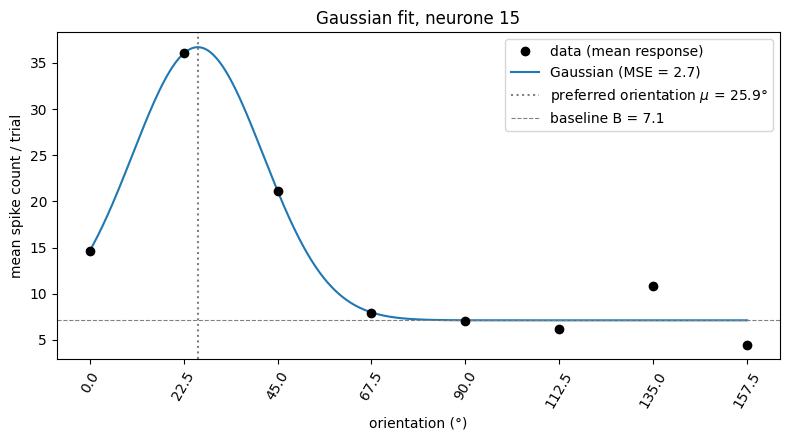

In [11]:
plt.figure(figsize=(8, 4.5))
plt.plot(theta, response, "ko", label="data (mean response)", zorder=5)
plt.plot(theta_fine, gaussian(theta_fine, B, A, mu, sigma), label=f"Gaussian (MSE = {gauss_mse:.1f})")
plt.axvline(mu, color="grey", ls=":", label=f"preferred orientation $\\mu$ = {mu:.1f}°")
plt.axhline(B, color="grey", ls="--", lw=0.8, label=f"baseline B = {B:.1f}")
plt.xlabel("orientation (°)")
plt.ylabel("mean spike count / trial")
plt.title(f"Gaussian fit, neurone {neurone}")
plt.xticks(theta, rotation=60)
plt.legend()
plt.tight_layout()
plt.show()

### Answers to the questions of Part 3

1. **Which model has the lowest MSE?** Among the models with fewer parameters than data points it is the Gaussian: MSE 2.7 with 4 parameters, against 4.7 for the 4th-order polynomial (5 parameters), 40.8 for the cubic and 53.7 for the line. Only degree 7 is lower (about 0) because it goes through all 8 points. The Gaussian follows the peak well but stays at the baseline afterwards, so it misses the bump at 135° (data 10.8, fit 7.1) and the low value at 157.5° (data 4.5, fit 7.1). These two points are most of its error.

2. **What is the preferred orientation $\mu$?** About 25.9°. The biggest measured response is at 22.5°, and the estimate is a bit higher because the response at 45° (21.1) is much larger than at 0° (14.7), which pulls the peak towards 45°.

3. **What does $\sigma$ tell you?** $\sigma$ $\approx$ 15.6° is the width of the peak. The full width at half height is $2.355\,\sigma \approx 37°$, so the neurone is fairly sharply tuned: at 67.5° (42° from $\mu$) the response (8.0) is already almost at the baseline (7.1). $\sigma$ is smaller than the 22.5° spacing of the orientations, so only two or three points describe the peak and $\sigma$ should be read with some caution.

4. **Which parameters have a biological meaning?** All four. $B \approx 7.1$ spikes is the baseline response, $A \approx 29.6$ spikes is the extra response at the preferred orientation (so the peak is $B + A \approx 36.7$), $\mu \approx 25.9°$ is the preferred orientation and $\sigma \approx 15.6°$ is the tuning width.

5. **Why might this model be preferable even if the MSEs are similar?** The MSE only measures the fit to the 8 points we have. The Gaussian has only 4 parameters, so it cannot just memorise the data. It is smooth and goes back to baseline away from the peak, while a polynomial can oscillate between measurements (degree 7 near 147°) or explode outside the measured range. And its parameters ($B$, $A$, $\mu$, $\sigma$) can be reported and compared between neurones. Here the Gaussian also has a lower MSE than the 4th-order polynomial with fewer parameters.

## 4. A problem with orientation

The models so far treat orientation as an ordinary number. But orientation is circular: 0° and 180° are the same stimulus, so 170° and 10° are close in orientation space although they are far apart as numbers. The questions below ask what this means for the models we have used.

### Answers to the questions about circularity

1. **Why is this a problem for the Gaussian of Part 3?** The Gaussian uses the ordinary difference $\theta-\mu$, so it treats 0° and 157.5° as 157.5° apart, the largest distance in our data. On the circle (period 180°) 157.5° is only 22.5° from 180°, which is the same as 0°, so these two stimuli are neighbours. The model does not know this and can give very different values to almost identical stimuli.

2. **Why would a Gaussian centred near 0° struggle across the 0°/180° boundary?** A neurone tuned near 0° responds strongly at the left end of the axis and again at the right end (near 157.5° and 180°), because that is the other side of the same peak. A Gaussian is a single bump on a straight line, so half of it would lie on negative angles and nothing makes it rise again near 180°. To reach both ends it would have to become very wide, or it would fit one side and miss the other.

3. **Why is polynomial regression also a problem?** A polynomial treats 0° and 180° as the two ends of a line, so the place where the circle is cut becomes part of the model. It is also not periodic: outside the measured range it keeps growing instead of repeating.

4. **How would this affect the neurone you selected?** Only a little. Neurone 15 prefers about 26° and its peak is narrow ($\sigma$ $\approx$ 16°). The Gaussian is already at baseline about 45–50° from the peak, so the part of the peak that would cross the boundary to 157.5° (49° away on the circle) is almost zero anyway. The error would matter much more for a neurone tuned right at 0°.

### The von Mises model

A standard model of orientation tuning that respects the circle is the von Mises function

$$R(\theta) = B + A\,\exp\!\big[\kappa\cos\big(2(\theta-\mu)\big)\big]$$

- $B$ is the baseline response (an offset added to the whole curve),
- $A$ controls the amplitude,
- $\mu$ is the preferred orientation,
- $\kappa$ controls how concentrated the curve is around $\mu$ (large $\kappa$ gives a narrow peak, $\kappa=0$ gives a flat curve).


In [12]:
def von_mises(theta, B, A, mu, kappa):
    return B + A * np.exp(kappa * np.cos(np.deg2rad(2 * (theta - mu)))) # angles in degrees; cos needs radians

# starting guesses: B = smallest response, A chosen so that the curve's peak-to-trough size matches the data,
# mu = each tested orientation, kappa = several concentrations
starts = [[response.min(), (response.max() - response.min()) / (np.exp(kappa0) - np.exp(-kappa0)), mu0, kappa0]
          for mu0 in theta for kappa0 in [0.5, 1, 2, 4, 8]]
vm_mse, vm_params, n_ok, n_best = fit_model(von_mises, theta, response, starts)

B_vm, A_vm, mu_vm, kappa = vm_params
mu_vm = mu_vm % 180 # the preferred orientation is defined modulo 180 degrees
print(f"{n_best} of {n_ok} converged starts reached the best fit")
print(f"B = {B_vm:.2f}, A = {A_vm:.2f}, mu = {mu_vm:.1f} deg, kappa = {kappa:.2f}")
print(f"lowest value of the curve = {B_vm + A_vm * np.exp(-kappa):.2f}, highest value = {B_vm + A_vm * np.exp(kappa):.2f}")
print(f"von Mises: 4 parameters, MSE = {vm_mse:.3f}  |  Gaussian: 4 parameters, MSE = {gauss_mse:.3f}")

27 of 40 converged starts reached the best fit
B = 7.02, A = 0.76, mu = 26.2 deg, kappa = 3.68
lowest value of the curve = 7.04, highest value = 37.04
von Mises: 4 parameters, MSE = 2.998  |  Gaussian: 4 parameters, MSE = 2.659


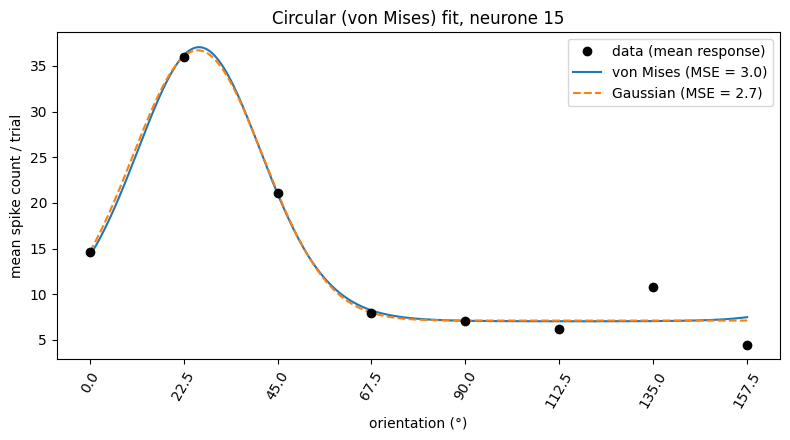

In [13]:
plt.figure(figsize=(8, 4.5))
plt.plot(theta, response, "ko", label="data (mean response)", zorder=5)
plt.plot(theta_fine, von_mises(theta_fine, B_vm, A_vm, mu_vm, kappa), label=f"von Mises (MSE = {vm_mse:.1f})")
plt.plot(theta_fine, gaussian(theta_fine, B, A, mu, sigma), "--", color="C1", label=f"Gaussian (MSE = {gauss_mse:.1f})")
plt.xlabel("orientation (°)")
plt.ylabel("mean spike count / trial")
plt.title(f"Circular (von Mises) fit, neurone {neurone}")
plt.xticks(theta, rotation=60)
plt.legend()
plt.tight_layout()
plt.show()

### Answers to the questions about the von Mises fit

1. **How does it compare with the Gaussian?** The curves are almost the same. Both peak at about 36–37 spikes near 26° and fall to a baseline of about 7 spikes by 67.5°. The MSE is about 3.0 for the von Mises and 2.7 for the Gaussian. Both miss the same points: the bump at 135° (data 10.8, both fits about 7) and the value at 157.5° (data 4.5, fits 7.1 and 7.5).

2. **What is the preferred orientation?** $\mu$ $\approx$ 26.2°, within half a degree of the Gaussian value (25.9°). The measured peak is at 22.5°.

3. **What does $\kappa$ tell you?** $\kappa$ $\approx$ 3.7 controls how concentrated the response is around $\mu$: larger $\kappa$ gives a narrower peak and $\kappa$ = 0 gives a flat curve. The full width at half height is about 36°, similar to the Gaussian (37°). So the neurone is sharply tuned.

4. **Why $2(\theta-\mu)$ and not $(\theta-\mu)$?** Orientation has period 180°. $\cos(2(\theta-\mu))$ repeats every 180°, so $\theta$ and $\theta$ + 180° give the same value, which is right because they are the same stimulus. Plain $\cos(\theta-\mu)$ repeats only every 360°, so 0° and 180° would be opposite points of the curve (peak and trough), as if the neurone could tell the two directions apart.

5. **Does accounting for circularity improve the fit?** No. The MSE is 3.0 against 2.7, slightly worse, but the difference is small. This is expected because the peak of neurone 15 is well inside the tested range and little of it crosses the 0°/180° boundary. It would matter for a neurone tuned right at the boundary.

6. **Which model would you choose?** von Mises. For this neurone it fits about as well as the Gaussian (both 4 parameters, MSE 3.0 vs 2.7), its parameters are just as easy to interpret, and it treats 0° and 180° as the same orientation, so it stays valid for neurones tuned near the boundary.

## 5. Comparing the models and evaluating generalization

So far the models were judged by how well they fit the data of one neurone. A model that fits the observed data very well is not necessarily the one that will do best on new data. In machine learning this is called generalization: how well a model captures the underlying relationship, and not the specific noise in the data it was fitted to.



### 5.1 Comparing different models

In [14]:
import pandas as pd

model_table = pd.DataFrame({
    "Model": ["Linear", "3rd-order polynomial", "4th-order polynomial", "7th-order polynomial", "Gaussian", "von Mises"],
    "Number of parameters": [2, 4, 5, 8, 4, 4],
    "MSE": [poly_mse[1], poly_mse[3], poly_mse[4], poly_mse[7], gauss_mse, vm_mse],
    "Biologically interpretable?": ["No", "No", "No", "No", "Yes", "Yes"],
    "Accounts for circularity?": ["No", "No", "No", "No", "No", "Yes"],
})
model_table["MSE"] = model_table["MSE"].round(2)
model_table

,Model,Number of parameters,MSE,Biologically interpretable?,Accounts for circularity?
0,Linear,2,53.69,No,No
1,3rd-order polynomial,4,40.76,No,No
2,4th-order polynomial,5,4.73,No,No
3,7th-order polynomial,8,0.00,No,No
4,Gaussian,4,2.66,Yes,No
5,von Mises,4,3.00,Yes,Yes


### 5.2 Comparing neurones with different noise levels

Neurone 15 is compared with two noisier neurones. The noise of a neurone is its trial-to-trial standard deviation (SD) of the spike count, averaged over the 8 orientations. The noisier neurones are drawn at random (seed 42) from those whose SD is more than twice that of neurone 15.

Three models are fitted to each neurone: the **Gaussian**, the **von Mises** and the **4th-order polynomial** (5 parameters, against 4 for the other two).

In [15]:
trial_sd = np.vstack([counts[stim == k].std(axis=0, ddof=1) for k in range(1, 9)])   # (8 orientations, n_neurones)
mean_sd = trial_sd.mean(axis=0)                                                       # typical trial-to-trial SD

noisy_candidates = np.flatnonzero(mean_sd > 2 * mean_sd[neurone])
noisy_neurones = [int(j) for j in np.random.default_rng(SEED).choice(noisy_candidates, size=2, replace=False)]
print(f"{len(noisy_candidates)} neurones with trial SD > 2 x {mean_sd[neurone]:.1f} = {2 * mean_sd[neurone]:.1f}:", noisy_candidates)
print("Noisier neurones drawn at random:", noisy_neurones)

neurones = [neurone, *noisy_neurones]
pd.DataFrame({
    "neurone": neurones,
    "mean count": counts.mean(axis=0)[neurones].round(1),
    "swing": swing[neurones].round(1),
    "trial SD": mean_sd[neurones].round(1),
}).set_index("neurone")

9 neurones with trial SD > 2 x 5.3 = 10.6: [ 38  57  75  95 106 121 127 147 149]
Noisier neurones drawn at random: [38, 127]


,mean count,swing,trial SD
neurone,,,
15,13.5,31.5,5.3
38,27.1,13.1,10.6
127,31.4,22.0,11.8


neurone 15: Gaussian mu = 25.9 deg, sigma = 15.6 deg | von Mises mu = 26.2 deg, kappa = 3.68


neurone 38: Gaussian mu = 28.6 deg, sigma = 13.5 deg | von Mises mu = 29.1 deg, kappa = 5.13
neurone 127: Gaussian mu = 29.6 deg, sigma = 18.5 deg | von Mises mu = 29.5 deg, kappa = 3.45


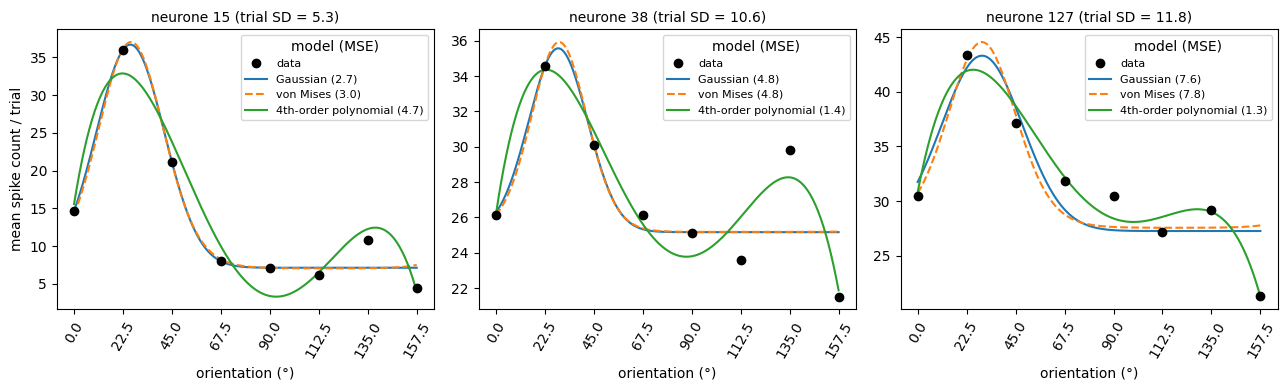

,Gaussian,von Mises,4th-order polynomial
neurone,,,
15,2.66,3.00,4.73
38,4.80,4.80,1.40
127,7.58,7.82,1.35


In [16]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
for ax, j in zip(axes, neurones):
    y = tuning[:, j]
    g_starts = [[y.min(), y.max() - y.min(), mu0, sigma0] for mu0 in theta for sigma0 in [10, 20, 40, 80]]
    v_starts = [[y.min(), (y.max() - y.min()) / (np.exp(kappa0) - np.exp(-kappa0)), mu0, kappa0]
                for mu0 in theta for kappa0 in [0.5, 1, 2, 4, 8]]
    g_mse, g_params, _, _ = fit_model(gaussian, theta, y, g_starts)
    v_mse, v_params, _, _ = fit_model(von_mises, theta, y, v_starts)
    coef4 = np.polyfit(theta, y, 4)
    mse4 = np.mean((y - np.polyval(coef4, theta)) ** 2)
    rows.append({"neurone": j, "Gaussian": g_mse, "von Mises": v_mse, "4th-order polynomial": mse4})
    print(f"neurone {j}: Gaussian mu = {g_params[2]:.1f} deg, sigma = {abs(g_params[3]):.1f} deg | "
          f"von Mises mu = {v_params[2] % 180:.1f} deg, kappa = {v_params[3]:.2f}")

    ax.plot(theta, y, "ko", label="data", zorder=5)
    ax.plot(theta_fine, gaussian(theta_fine, *g_params), label=f"Gaussian ({g_mse:.1f})")
    ax.plot(theta_fine, von_mises(theta_fine, *v_params), "--", label=f"von Mises ({v_mse:.1f})")
    ax.plot(theta_fine, np.polyval(coef4, theta_fine), label=f"4th-order polynomial ({mse4:.1f})")
    ax.set_title(f"neurone {j} (trial SD = {mean_sd[j]:.1f})", fontsize=10)
    ax.set_xticks(theta)
    ax.tick_params(axis="x", labelrotation=60)
    ax.set_xlabel("orientation (°)")
    ax.legend(fontsize=8, title="model (MSE)")
axes[0].set_ylabel("mean spike count / trial")
fig.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("neurone").round(2)

### Answers to the questions of Part 5

1. **Compare the goodness of fit of the models for the two noisier neurones.** The Gaussian and the von Mises fit almost identically (MSE 4.8 and 4.8 for neurone 38, 7.6 and 7.8 for neurone 127), and both are clearly worse than the 4th-order polynomial (1.4 and 1.3). For neurone 15 it was the other way round (2.7 and 3.0 against 4.7). The figure shows why: both noisier neurones peak near 23° like neurone 15, but they rise again at 135° (about 29 spikes) and drop at 157.5° (about 21). The Gaussian and von Mises must return to a constant baseline and miss both points, while the polynomial can follow some of this. Taking circularity into account does not help for either neurone.

2. **How does the noise change the relative performance?** On the data they were fitted to, the flexible polynomial gains an advantage: it goes from worse than the bump models on neurone 15 to 3–6 times better on the noisier neurones. The tuning of these neurones is weak compared with the noise: the swing is 13 and 22 spikes, while single trials vary by 11–12 spikes. Note that each mean is an average over 400 trials, so its standard error is small (about 0.5 spikes). With only a few trials per orientation the means would be much noisier, and then a flexible model would start to fit noise. I did not test this.

3. **Is the model with the lowest MSE necessarily the best at generalising?** No. For the noisier neurones the lowest MSE belongs to the 4th-order polynomial, and in 5.1 the 7th-order polynomial has an MSE of exactly 0 just because it has 8 parameters for 8 points, which says nothing about its predictions (for neurone 15 it invents a bump near 147°). A more flexible model can never have a larger error on the points it was fitted to. To measure generalisation we need data that were not used for the fit, which I did not do here.

4. **Which model would you choose to predict the response to a new orientation?** The von Mises. Tuning curves are smooth with one preferred orientation, and the von Mises builds this in: it has only 4 parameters, it cannot oscillate between measurements, it returns to baseline away from the peak, its parameters can be compared between neurones, and it treats 0° and 180° as the same orientation. The polynomials are less trustworthy: the 7th-order has no data left over and the 4th-order has no biological meaning and ignores circularity. The more flexible a model is, the more of the random scatter in the means it can absorb, and this matters more for noisier neurones, so a simpler model is safer for them. The price is bias: for neurones 38 and 127 the bump models miss structure that the polynomial fits (MSE 4.8 and 7.8 against 1.4 and 1.3), and I cannot say from this data how much of it is real. This should be checked with held-out data, for example with cross-validation.